# HER 2match: flow matching experiments and targeted staining fixes

Five completed experiments from the final presentation: **Noise CFM**, **Direct CFM**, **Direct + LPIPS**, **Direct + stain-aware sampling**, and **Direct + staining loss**. There is **no optimal-transport reassignment and no bridge experiment** in this submission.

The runs were executed with Python scripts and inspected through notebooks. This notebook consolidates their execution workflow, exact objectives, saved learning curves, test scores, and fixed image examples. Recorded results are supplied separately from new training outputs. Running this notebook as shipped **reviews completed results without launching training**.

Training uses aligned HER 2match only. Final evaluation uses the same **252 native-resolution pairs, 63 per slide-level HER 2 score**. The original 100 inspected examples remain in this follow-up cohort.

## Setup

Install `requirements-her 2match.txt` in a dedicated environment. Choose a compatible CUDA PyTorch build. To retrain, obtain [HER 2match](https://www.kaggle.com/datasets/asmaayaser/her 2match-dataset) and set `HER 2_DATA_ROOT` to the extracted directory containing `tiles/HE/{train,val,test}` and `tiles/IHC/{train,val,test}`.

Set `CUDA_VISIBLE_DEVICES` **before importing PyTorch**. The code respects that choice; no physical GPU is hard-coded. Data and checkpoints are not committed. The small image panels are actual recorded predictions and matching references.

In [1]:
from pathlib import Path
import os, sys, json, csv, inspect
from IPython.display import display, HTML, Image
REPO = Path.cwd().resolve()
if (REPO / "HER2Match/her2match").is_dir():
    REPO = REPO / "HER2Match"
if not (REPO / "her2match").is_dir():
    raise RuntimeError("Run this notebook from the repository root or HER2Match directory")
sys.path.insert(0, str(REPO / "her2match"))
# Before enabling training, set HER2_DATA_ROOT and CUDA_VISIBLE_DEVICES externally.
RUN_TRAINING = False
RESULTS = REPO / "results/her2match"  # Saved completed runs; new runs use outputs/.
import baseline
import fixes
print("Reviewing recorded results. Training enabled:", RUN_TRAINING)


Reviewing recorded results. Training enabled: False


## Shared protocol and split audit

Same ConditionalUNet (channels 32/64/128/256, two residual blocks per level), initial model weights, seed 42, paired 512×512 crops and synchronized augmentation. Effective batch 8 (microbatch 2 × accumulation 4). AdamW, learning rate 1e-4,500-update warmup, cosine decay,20,000 optimizer updates, EMA 0.999. Save/resume every 500 updates; reject incompatible configurations.

Checkpoints are selected by the highest **EMA validation SSIM on the original fixed 16 center crops**, with Heun 16. This preserves the original control; the two fixes additionally record 48 validation examples without using them for selection. Test images never select checkpoints. Official slide splits are disjoint; patient identities are unavailable. Labels are slide-level, not patch diagnoses.

In [2]:
from collections import Counter
records = [json.loads(line) for line in (REPO/"her2match/manifests/HER2match.jsonl").read_text().splitlines()]
test = [json.loads(line) for line in (REPO/"her2match/manifests/test252.jsonl").read_text().splitlines()]
groups = {split: {r["group"] for r in records if r["split"] == split} for split in ("train", "val", "test")}
assert not (groups["train"] & groups["val"] or groups["train"] & groups["test"] or groups["val"] & groups["test"])
assert len(test) == len({r["id"] for r in test}) == 252
assert Counter(r["her2_score"] for r in test) == {"0":63, "1+":63, "2+":63, "3+":63}
print("Split sizes:", dict(Counter(r["split"] for r in records)))
print("Test slide scores:", dict(Counter(r["her2_score"] for r in test)))
print("Test slide counts:", dict(Counter(r["group"] for r in test)))


Split sizes: {'train': 11610, 'val': 3582, 'test': 5980}
Test slide scores: {'0': 63, '1+': 63, '2+': 63, '3+': 63}
Test slide counts: {'wsi001': 32, 'wsi016': 31, 'wsi008': 63, 'wsi012': 63, 'wsi009': 63}


## Objectives: Noise, Direct, and Direct + LPIPS

Let $c$ be H&E, $y$ paired real IHC, and $t\sim U(0,1)$.

- **Noise CFM:** $z\sim N(0,I)$; $x_t=(1-t)z+ty$; target velocity $y-z$. Gaussian inference source, fixed H&E condition.
- **Direct CFM:** $x_t=(1-t)c+ty$; target velocity $y-c$. H&E inference source, same fixed H&E condition; no trajectory noise.
- **Direct + LPIPS:** Direct FM MSE plus $0.1\,LPIPS(\hat y,y)$, with $\hat y=x_t+(1-t)v_\theta(x_t,t,c)$. Frozen AlexNet LPIPS; matching 256×256 crops; RGB[-1,1]; clamp only the perceptual image input. Gradients still reach the generator. This is a one-step estimate, not an ODE rollout.

The following cell shows the actual training function used by the portable runner.

In [3]:
print(inspect.getsource(baseline.losses))
print(inspect.getsource(baseline.source_image))


def losses(model,perceptual,name,c,y,micro_index,check=False):
    rng=torch.Generator(device='cuda').manual_seed(stable_seed(42,f'path:{micro_index}'))
    z=torch.randn(c.shape,generator=rng,device=c.device)
    t=torch.rand((len(c),1,1,1),generator=rng,device=c.device)
    source=z if name=='noise_cfm' else c
    xt=(1-t)*source+t*y
    with torch.autocast('cuda',dtype=torch.bfloat16):v=model(xt,t.flatten(),c)
    fm=(v.float()-(y-source)).square().mean()
    raw=torch.zeros((),device=c.device)
    if perceptual is not None:
        endpoint=xt+(1-t)*v.float()
        rng_crop=random.Random(stable_seed(42,f'lpips:{micro_index}'))
        ps,ys=[],[]
        for i in range(len(c)):
            top=rng_crop.randrange(c.shape[-2]-256+1);left=rng_crop.randrange(c.shape[-1]-256+1)
            ps.append(endpoint[i,:,top:top+256,left:left+256]);ys.append(y[i,:,top:top+256,left:left+256])
        raw=perceptual(torch.stack(ps).clamp(-1,1),torch.stack(ys)).mean()
        if check:
          

## Targeted fix 1: stain-aware sampling

The audit found approximately 72% of sampled training crops had ≤1% stained tissue. We indexed nine native 512px crops per training pair (offsets 0/256/512), required ≥20% tissue, and split candidates into low≤1%, medium 1–10%, and high>10% DAB coverage. Effective batches contain 3/2/3 crops from these strata; sample slide, tile, then crop within a stratum. H&E and IHC share coordinates and spatial augmentation.

This changes sampling only; it retains the Direct FM loss. It does not use clinical test labels or reassign pairs. The implementation fails if a required eligible stratum is empty.

In [4]:
print(inspect.getsource(fixes.FixBatches))


class FixBatches(b.TrainingBatches):
 def __iter__(self):
  if ACTIVE!=NEW[0]:yield from super().__iter__();return
  ds=StainDataset();pattern=(0,1,2,0,2,1,0,2);batch=self.start_batch
  while True:
   keys=[]
   for j in range(self.batch_size):
    index=batch*self.batch_size+j;stratum=pattern[index%8];rng=random.Random(b.stable_seed(42,f'balanced-crop:{index}'))
    groups=ds.pools[stratum];g=rng.choice(sorted(groups));tile=rng.choice(sorted(groups[g]));crop=rng.choice(groups[g][tile]);keys.append((crop,b.stable_seed(42,f'crop-augment:{index}')))
   yield keys;batch+=1



## Targeted fix 2: staining-sensitive endpoint loss

Keep the original sampling and add `0.1 × balanced_dab(endpoint, target)` to velocity MSE. DAB error is divided by the fixed 0.1 concentration scale. Average absolute error separately over stained and unstained GT tissue, then over images; omit empty regions. The DAB threshold 0.02 comes from the saved validation calibration.

Only auxiliary RGB is clamped. The nonnegative DAB projection uses a straight-through gradient so missing brown staining can still receive a gradient when raw predicted DAB is negative. Velocity is never clipped. The weight was fixed before training. This optical proxy is not a tumor-cell or membrane segmentation loss.

In [5]:
print(inspect.getsource(fixes.dab_tensor))
print(inspect.getsource(fixes.balanced_dab))
print(inspect.getsource(fixes.losses))


def dab_tensor(x):
 rgb=(x.float()+1)/2
 # Clamp only auxiliary RGB input; do not amplify gradients outside RGB range.
 # DAB nonnegative projection below uses a straight-through gradient so
 # missing brown stain still receives a gradient at negative raw DAB.
 rgb=rgb.clamp(1e-6,1)
 od=torch.log(rgb)/math_log_eps
 matrix=torch.as_tensor(hed_from_rgb[:,2],device=x.device,dtype=torch.float32)
 raw=torch.einsum('bchw,c->bhw',od,matrix)
 return raw+(raw.clamp_min(0)-raw).detach()

def balanced_dab(endpoint,target):
 pd=dab_tensor(endpoint);gd=dab_tensor(target).detach();rgb=((target+1)/2).detach();mean=rgb.mean(1);maximum=rgb.amax(1);minimum=rgb.amin(1)
 saturation=(maximum-minimum)/maximum.clamp_min(1e-6)
 mask=((saturation>.08)&(mean<.97))|(mean<.9)
 # Exact binary opening + closing with scipy default cross footprint.
 cross=torch.tensor([[0,1,0],[1,1,1],[0,1,0]],device=target.device,dtype=torch.float32)[None,None]
 def erode(m):return torch.nn.functional.conv2d(m[:,None].float(),cross,

## Optional sequential rerun

Enable `RUN_TRAINING` only after setting the data and GPU environment variables. All GPU work below is sequential. The original three runs are followed by the two fixes. The runners perform real-data smoke tests, finite-gradient checks, crop synchronization checks, correct-source checks, and timing/memory measurements. Outputs include EMA best checkpoints, resumable latest checkpoints, histories, PNG predictions, per-image metrics, and combined results.

The exported code has portable paths and a HER 2match-only evaluator; its configuration hashes intentionally differ from the archived server runs. Do not resume archived checkpoints under the new identity. The mathematical objectives, architecture, sampling, solver, and training schedule are retained.

In [6]:
import subprocess
if RUN_TRAINING:
    assert os.environ.get("HER2_DATA_ROOT"), "Set HER2_DATA_ROOT first"
    assert os.environ.get("CUDA_VISIBLE_DEVICES"), "Allocate a GPU explicitly first"
    subprocess.run([sys.executable, "her2match/baseline.py"], check=True, cwd=REPO)
    subprocess.run([sys.executable, "her2match/fixes.py", "scan"], check=True, cwd=REPO)
    subprocess.run([sys.executable, "her2match/fixes.py", "run"], check=True, cwd=REPO)
else:
    print("Training skipped; the following sections use saved completed-run results.")


Training skipped; the following sections use saved completed-run results.


## Completed training: original three experiments

Training shows the FM component only, with a 100-update moving average on a log axis. Different source distributions imply different velocity targets, so lower FM loss across Noise/Direct is not a quality ranking. Validation uses the same 16 images, EMA, and Heun 16; dots mark selected checkpoints.

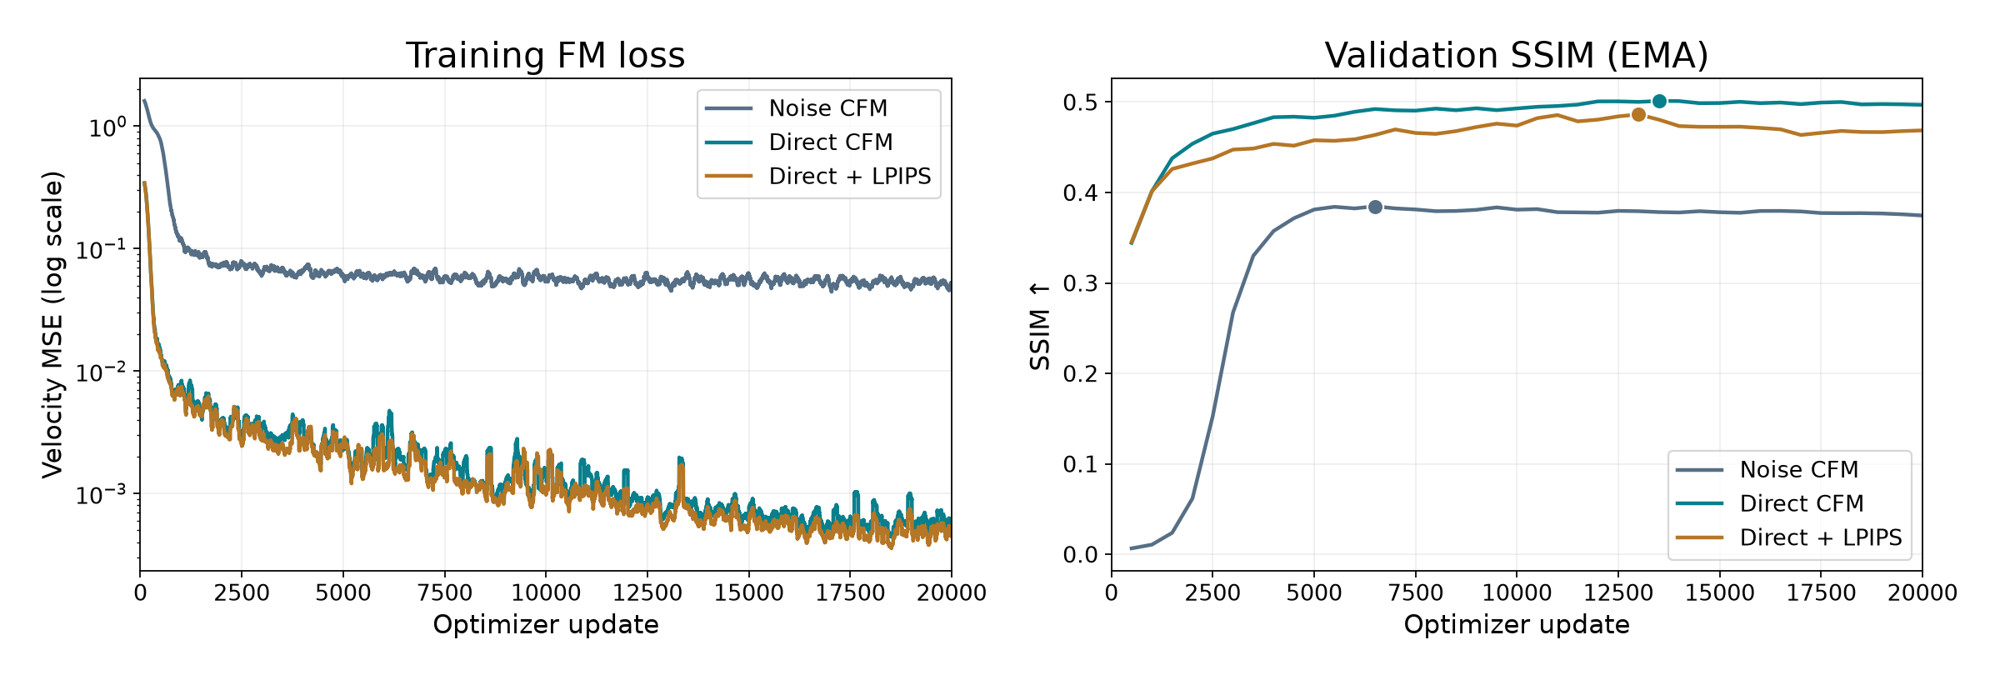

noise_cfm updates: 20000 selected: 6500 validation SSIM: 0.3848
direct_cfm updates: 20000 selected: 13500 validation SSIM: 0.5012
direct_cfm_lpips updates: 20000 selected: 13000 validation SSIM: 0.4864
direct_cfm_stain_sampling updates: 20000 selected: 16000 validation SSIM: 0.507
direct_cfm_stain_loss updates: 20000 selected: 15500 validation SSIM: 0.486


In [7]:
display(Image(filename=str(RESULTS/"figures/slide_1.jpg")))
for name in fixes.ALL:
    summary = json.loads((RESULTS/"runs"/name/"recorded_metrics.json").read_text())
    print(name, "updates:", summary["optimizer_updates"], "selected:", summary["selected_update"],
          "validation SSIM:", round(summary["best_validation_ssim"], 4))


## Training histories for all five reported methods

These are saved curves from the completed runs, including the two fixes. Total losses have different definitions across objectives and are not a common quality score. The validation rule is identical across runs.

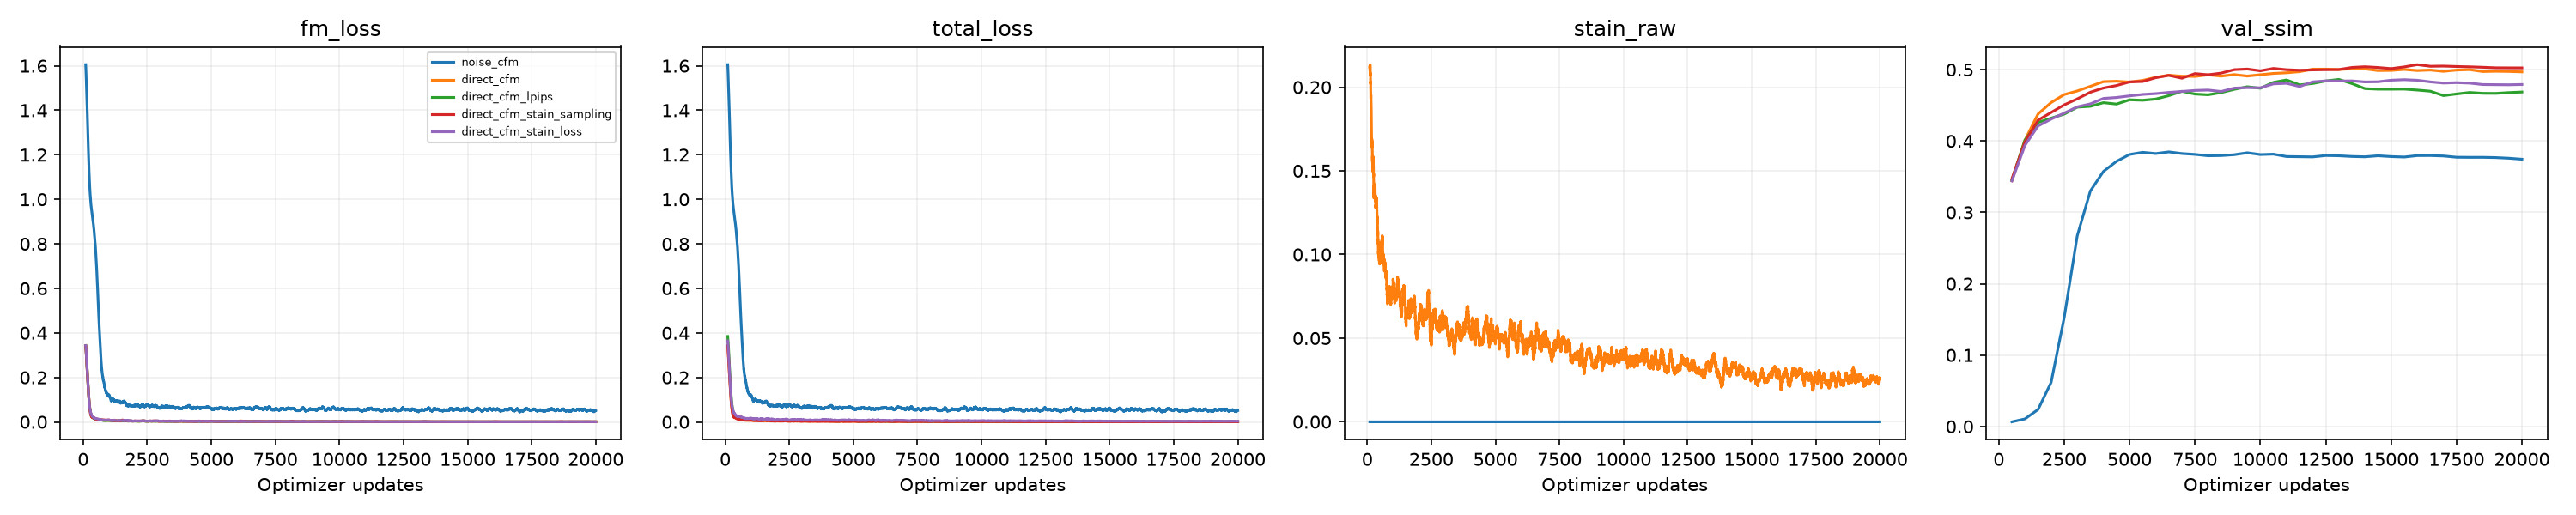

In [8]:
display(Image(filename=str(RESULTS/"figures/all_five_training.jpg")))

## Identical 252-pair test evaluation

Full native 1024×1024 inference, without resizing/cropping, Heun 16. Save quantized PNGs before scoring. LPIPS-AlexNet uses RGB[-1,1]; FID/KID use pytorch-fid Inception pool 3 (2048 features; internal 299px preprocessing). KID uses 100 subsets of 100, seed 42. FID/KID measure distributions, not input-output correspondence. Stain proxies use the same validation-calibrated transform and GT tissue support for every method. Missing/false areas are percentages of all GT tissue, not sensitivity/specificity.

The saved per-image CSVs, histories, checkpoint hashes, class summaries, and environment versions are in `results/her 2match`.

In [9]:
import html
with (RESULTS/"comparison.csv").open() as f:
    scores = list(csv.DictReader(f))
columns = [("model", "Method", None), ("count", "N", None),
           ("ssim", "SSIM ↑", 3), ("psnr_db", "PSNR ↑", 2), ("lpips", "LPIPS ↓", 3),
           ("fid", "FID ↓", 2), ("kid", "KID ↓", 4), ("dab_mae", "DAB MAE ↓", 5),
           ("missing_stain", "Missing % ↓", 2), ("false_stain", "False % ↓", 2),
           ("stain_iou", "Stain IoU ↑", 4), ("edge_ratio", "Edges ≈1", 3)]
def formatted(row, key, precision):
    if precision is None: return html.escape(row[key])
    value = float(row[key]) * (100 if key in ("missing_stain", "false_stain") else 1)
    return f"{value:.{precision}f}"
head = "<tr>" + "".join("<th>"+label+"</th>" for _,label,_ in columns) + "</tr>"
body = "".join("<tr>"+"".join("<td>"+formatted(r,k,d)+"</td>" for k,_,d in columns)+"</tr>" for r in scores)
display(HTML("<table>"+head+body+"</table>"))

Method,N,SSIM ↑,PSNR ↑,LPIPS ↓,FID ↓,KID ↓,DAB MAE ↓,Missing % ↓,False % ↓,Stain IoU ↑,Edges ≈1
noise_cfm,252,0.319,17.74,0.502,221.79,0.2187,0.01594,7.65,0.46,0.0054,0.786
direct_cfm,252,0.397,18.86,0.456,151.32,0.0990,0.01594,7.61,0.90,0.0043,0.539
direct_cfm_lpips,252,0.388,18.89,0.482,131.26,0.0815,0.01548,7.93,0.01,0.0003,0.592
direct_cfm_stain_sampling,252,0.408,19.02,0.461,158.09,0.1130,0.01551,7.62,0.19,0.0041,0.500
direct_cfm_stain_loss,252,0.390,18.86,0.444,150.93,0.0987,0.01599,7.80,0.58,0.0130,0.564


## What the images revealed

Top row: false staining. Bottom row: missing strong staining. These 256×256 crops were fixed before the two new experiments, and are identical across methods. Noise, Direct and Direct+LPIPS are compared with real IHC. Higher SSIM does not guarantee the correct marker signal.

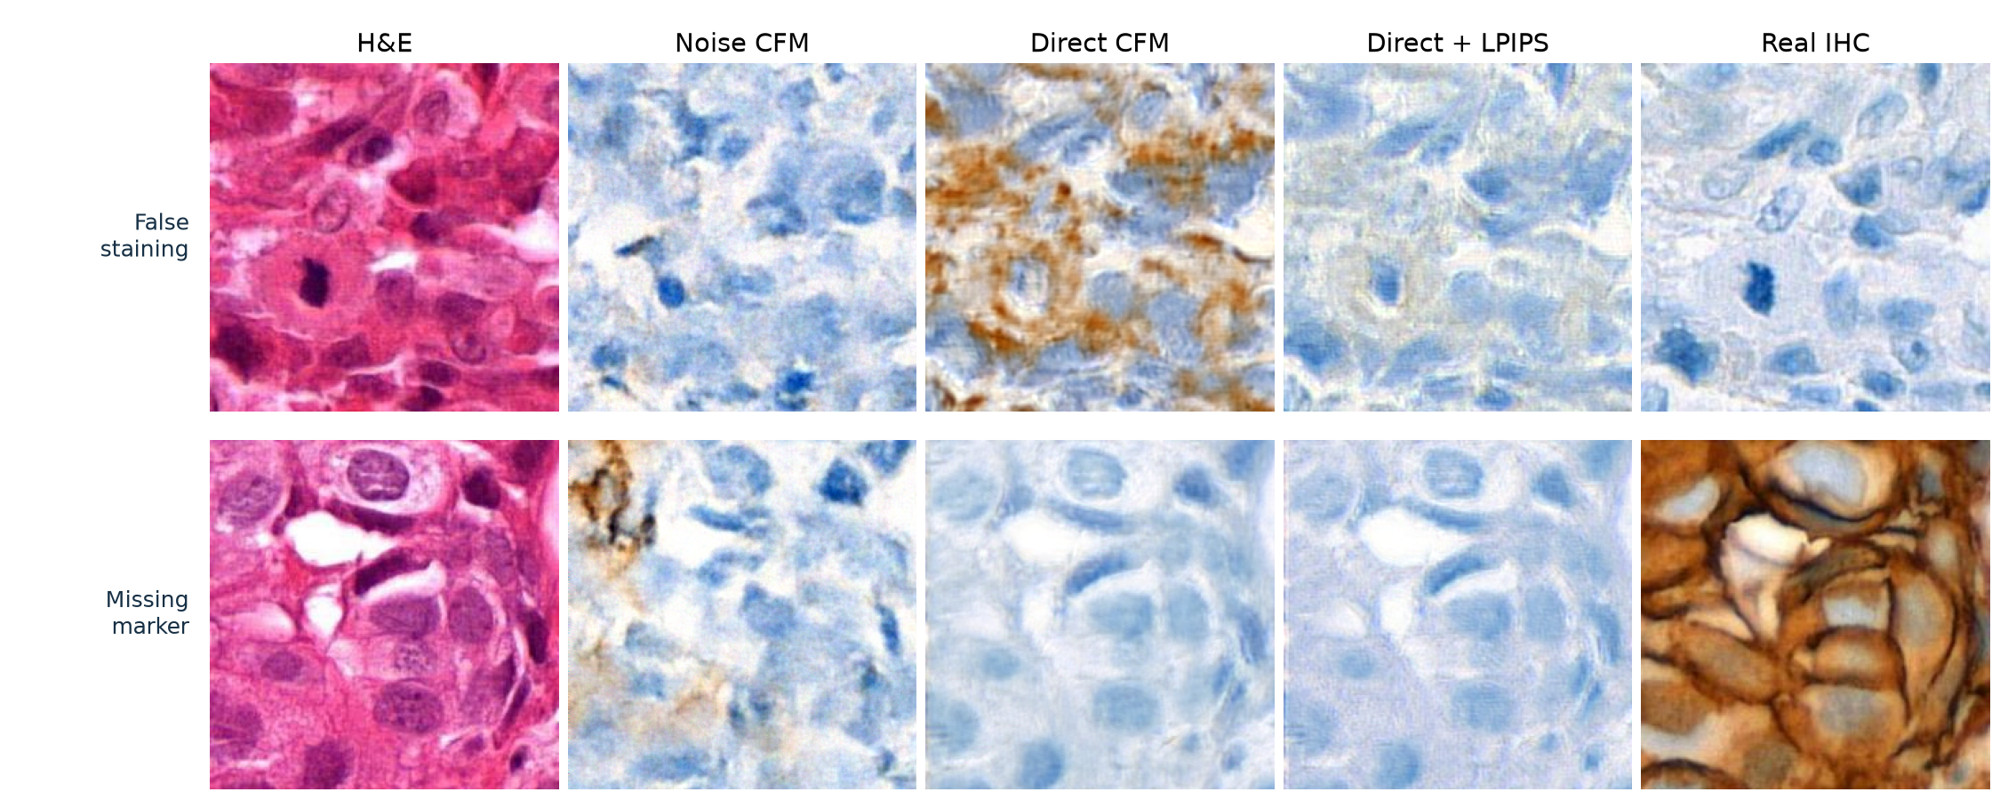

In [10]:
display(Image(filename=str(RESULTS/"figures/slide_2.jpg")))


## Did the fixes help?

The same two cases compare Direct with sampling and staining loss. In the false-staining example, full-patch stained area decreases from 37.89% with Direct to 6.01% with sampling and 5.09% with staining loss, versus 0.08% GT. The error is reduced, not eliminated.

In the positive example, real IHC has 73.35% stained tissue; sampling predicts 0.017%, and staining loss 0.55%. The marker is still largely absent.

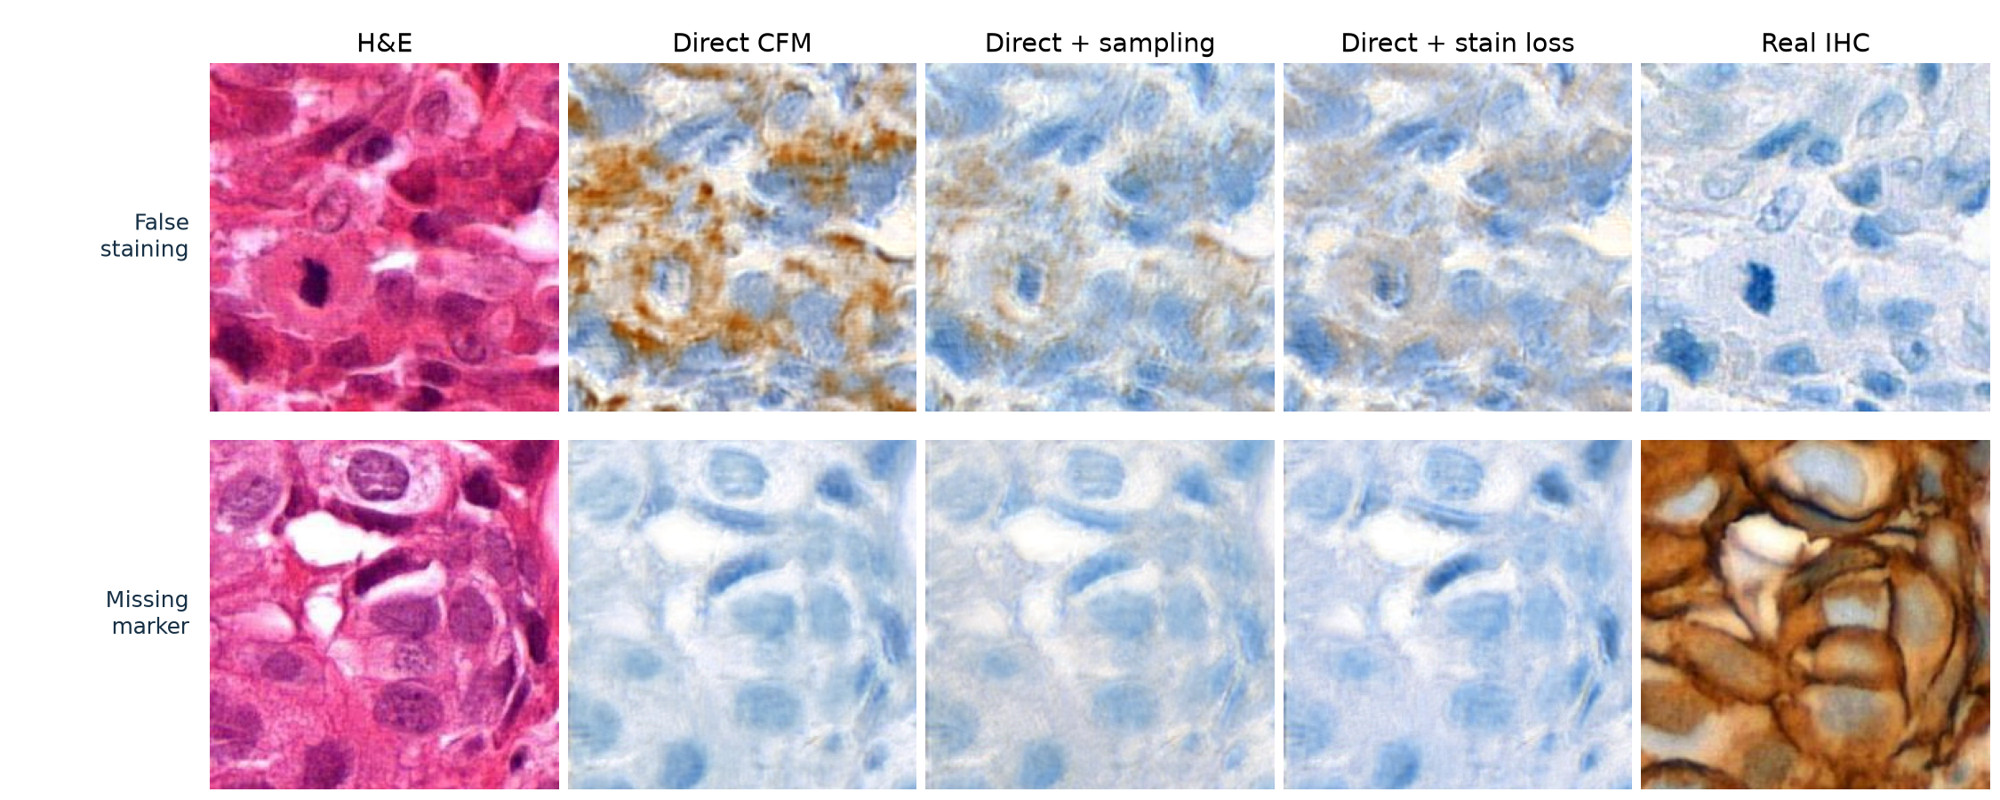

In [11]:
display(Image(filename=str(RESULTS/"figures/slide_3.jpg")))


## Remaining weakness: positive staining and fine detail

Top row: the positive example. Bottom row: the original detail-loss example. All five methods use matching crops. For the latter, edge strength relative to GT is 0.34 for Direct,0.33 for sampling, and 0.38 for staining loss: only a small change, not demonstrated recovery of cellular structure.

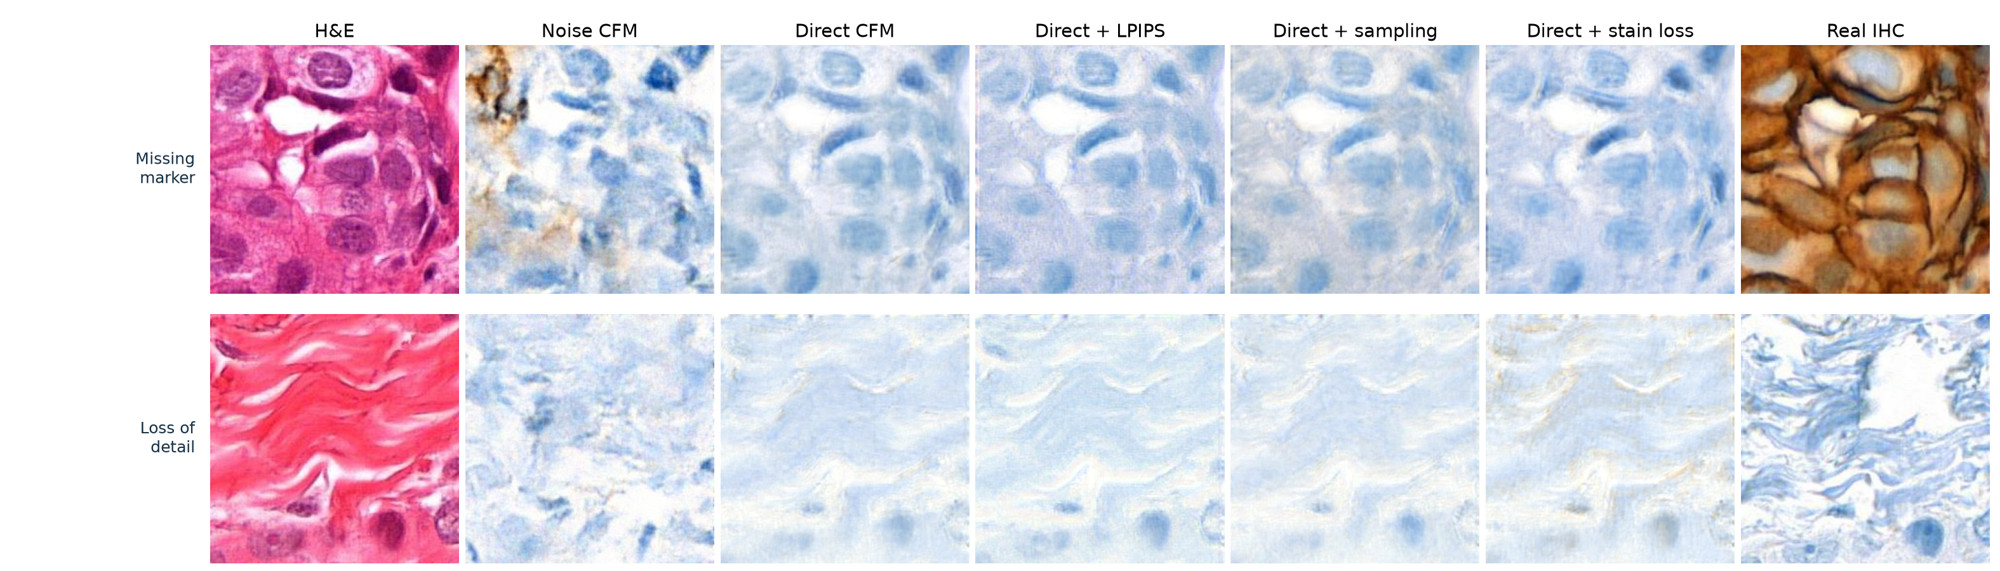

In [12]:
display(Image(filename=str(RESULTS/"figures/slide_4.jpg")))


## Conclusion

- **Sampling** gives the highest SSIM(0.408) and PSNR(19.02dB), and reduces average false-stain area from 0.90% to 0.19%.
- **Staining loss** gives the best LPIPS(0.444); false-stain area decreases to 0.58% and staining-mask overlap improves.
- **Neither fix solves missing staining:** Direct 7.61%, sampling 7.62%, staining loss 7.80% mean missing-stain area. Detail remains weak. Direct+LPIPS suppresses false staining most strongly but misses the most real staining.

There is no overall winner for HER 2 fidelity. These are descriptive results on an inspected, slide-correlated follow-up cohort; slide scores and optical staining proxies are not clinical patch classifications.